In [17]:
import numpy as np
import glob
from pathlib import Path
import matplotlib.pyplot as plt 

In [18]:
BASE_DIR = Path("/home/kiemax/Helmholtz/projects/proteinTPM/noripTPM/data/sabdab/interfaces/Carboxamid_start_atm")

In [19]:
BASE_DIR / "data_by_pdb"/ "*.pdb"

PosixPath('/home/kiemax/Helmholtz/projects/proteinTPM/noripTPM/data/sabdab/interfaces/Carboxamid_start_atm/data_by_pdb/*.pdb')

In [20]:
MAX_NEIGHBOURS= 25

In [21]:
broom_data = glob.glob(str(BASE_DIR / "data_by_pdb"/"*.npz"))

In [22]:
len(broom_data)

6287

In [23]:
def pad_array(arr, target_rows):
    """Pad or trim the array to have exactly target_rows rows."""
    if arr.shape[0] >= target_rows:
        return arr[:target_rows]
    else:
        padding = np.zeros((target_rows - arr.shape[0], arr.shape[1]), dtype=arr.dtype)
        return np.vstack([arr, padding])

def process_triplet(triplet):
    """
    Process a single triplet to extract:
      - target positions (all columns except the first and last)
      - target classes (first column, reshaped as a column vector)
      - chart orientation
    Each of the first two arrays is padded (or trimmed) to have MAX_NEIGHBOURS rows.
    """
    # Extract and pad target positions.
    positions = pad_array(triplet["target_atoms"][:, 1:-1], MAX_NEIGHBOURS)
    
    # Extract and pad target classes.
    target_atms = triplet["target_atoms"][:, 0] #+1 <--  from old version, problem with zero padding now handled in map_atoms()
    #print(target_atms)
    classes = pad_array(target_atms.reshape(-1, 1), MAX_NEIGHBOURS)
    
    # Extract chart orientation (assumed to be already in the desired shape).
    #chart_ori = triplet["chart_orientation"]
    
    return positions, classes #, chart_ori

In [24]:
target_positions = list()
target_classes = list()
pdb_id = list()

for id,path in enumerate(broom_data):
    
    with np.load(path, allow_pickle=True) as data:
        triplets = data["triplets"]
        for triplet in triplets:
            #positions, classes, chart_ori = process_triplet(triplet)
            positions, classes = process_triplet(triplet)
            target_positions.append(positions)
            target_classes.append(classes)
            pdb_id.append(id)
            #chart_orientations.append(chart_ori)
brooms_stack = np.stack(target_positions)


In [25]:
def find_largest(data):
    magnitudes = np.linalg.norm(data, axis=2)  # shape: (N, n)

    max_idx = np.unravel_index(np.argmax(magnitudes), magnitudes.shape)

    return max_idx

In [26]:
def sorted_indices_by_magnitude(data):
    """
    Given `data` of shape (N, M, K), compute the L2‑norm over the last axis
    (yielding an (N, M) array of magnitudes) and return all (i, j) pairs
    sorted in descending order of magnitude.
    
    Returns
    -------
    indices : List[Tuple[int, int]]
        A list of (row, col) index tuples, sorted so that the first element
        corresponds to the largest magnitude in the array, and so on.
    """
    # compute magnitudes
    magnitudes = np.linalg.norm(data, axis=2)  # shape: (N, M)
    flat_order = np.argsort(magnitudes.ravel())[::-1]
    mags = magnitudes.ravel()[flat_order]
    
    # flatten & argsort descending
    flat_sorted = np.argsort(magnitudes.ravel())[::-1]

    # map back to 2D indices
    rows, cols = np.unravel_index(flat_sorted, magnitudes.shape)

    # pair them up
    return list(zip(rows, cols)), mags

In [27]:
idxs,mags = sorted_indices_by_magnitude(brooms_stack)

In [28]:
idxs

[(21438, 24),
 (21438, 23),
 (11714, 24),
 (11714, 23),
 (21438, 22),
 (11714, 22),
 (11714, 21),
 (6896, 24),
 (6896, 23),
 (11286, 24),
 (6896, 22),
 (11714, 20),
 (11286, 23),
 (21438, 21),
 (1576, 24),
 (11047, 24),
 (840, 24),
 (12661, 24),
 (11047, 23),
 (11714, 19),
 (16746, 24),
 (12661, 23),
 (11047, 22),
 (6896, 21),
 (8175, 24),
 (11237, 24),
 (11047, 21),
 (11286, 22),
 (11714, 18),
 (11237, 23),
 (840, 23),
 (6896, 20),
 (16746, 23),
 (7897, 24),
 (1576, 23),
 (5125, 24),
 (11047, 20),
 (11286, 21),
 (11047, 19),
 (11237, 22),
 (8175, 23),
 (8175, 22),
 (21438, 20),
 (6896, 19),
 (840, 22),
 (8175, 21),
 (1576, 22),
 (10366, 24),
 (12661, 22),
 (16746, 22),
 (12744, 24),
 (7106, 24),
 (11714, 17),
 (12661, 21),
 (8175, 20),
 (12661, 20),
 (10366, 23),
 (11047, 18),
 (7897, 23),
 (1576, 21),
 (12744, 23),
 (3902, 24),
 (1576, 20),
 (7106, 23),
 (5125, 23),
 (840, 21),
 (1576, 19),
 (11286, 20),
 (1576, 18),
 (7897, 22),
 (453, 24),
 (11237, 21),
 (5125, 22),
 (241, 24),
 (1

In [29]:
broom_data[pdb_id[idxs[-1][0]]]

'/home/kiemax/Helmholtz/projects/proteinTPM/noripTPM/data/sabdab/interfaces/Carboxamid_start_atm/data_by_pdb/6mwv.npz'

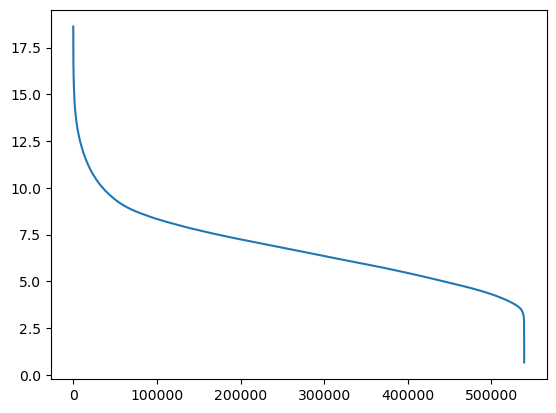

In [30]:
plt.plot(mags)

In [91]:
np.where(mags > 14.5)


(array([    0,     1,     2, ..., 22781, 22782, 22783]),)

In [92]:
len(mags)

1262600

In [93]:
len(set([pdb_id[i[0]] for i in idxs[:22784]]))

2397

In [14]:
max_idx = find_largest(brooms_stack)
max_idx

(6628, 24)

In [15]:
pdb_id[max_idx[0]]

1918

In [27]:
broom_data[pdb_id[idxs[0][0]]]

'/home/kiemax/Helmholtz/projects/proteinTPM/noripTPM/data/sabdab/interfaces/Carboxamid_start_atm/data_by_pdb/3j42.npz'

In [18]:
broom_data[0]

'/home/kiemax/Helmholtz/projects/proteinTPM/noripTPM/data/sabdab/interfaces/Carboxamid_start_atm/data_by_pdb/7dge.npz'

In [19]:
brooms_stack[idxs[2][0], :,:]

array([[ -1.965,  -3.533,  -4.997],
       [ -4.705,  -7.1  ,  -1.787],
       [ -5.549,  -4.818,  -4.707],
       [ -0.926,  -7.166,  -5.419],
       [  0.631,  -9.796,  -3.134],
       [ -3.504, -10.697,  -1.697],
       [  1.179, -13.361,  -4.333],
       [ -4.263, -12.884,  -4.719],
       [ -8.834, -11.407,  -6.91 ],
       [ -7.018, -10.737, -10.138],
       [ -0.298, -16.673,  -3.214],
       [  0.726, -11.034, -13.605],
       [ -4.922, -16.617,  -4.378],
       [ -0.866,  -8.763, -16.227],
       [  0.748,  -5.643, -17.626],
       [  6.316, -14.012, -10.633],
       [-10.012, -15.002,  -6.779],
       [  6.695, -11.941, -13.821],
       [  4.228, -10.203, -16.2  ],
       [ -6.88 , -12.735, -13.374],
       [ -3.415, -14.276, -13.786],
       [ -7.637, -16.843,  -9.099],
       [ -0.443, -20.02 ,  -5.04 ],
       [ -4.784, -18.667,  -7.575],
       [  2.287, -14.26 , -14.963]], dtype=float32)

In [20]:
np.linalg.norm(brooms_stack[max_idx[0], :,:], axis=1)

array([ 8.9344015,  9.633683 ,  9.682826 , 11.091991 , 11.524541 ,
       11.971269 , 13.403561 , 13.534366 , 13.842361 , 13.84471  ,
       14.1020355, 14.103645 , 15.43156  , 16.32457  , 17.141296 ,
       17.367214 , 18.625563 , 19.772438 , 20.483702 , 20.686758 ,
       20.74347  , 20.758516 , 21.389067 , 21.445839 , 21.760897 ],
      dtype=float32)

In [20]:
with np.load(BASE_DIR/ "target_positions_all.npz", allow_pickle=True) as dat:

    data = dat["arr"]

In [21]:
data[max_idx[0],:25,:] == brooms_stack[max_idx[0], :,:]


array([[ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True],
       [ True,  True,  True]])

In [22]:
data[max_idx[0],:25,:]

array([[ -1.965,  -3.533,  -4.997],
       [ -4.705,  -7.1  ,  -1.787],
       [ -5.549,  -4.818,  -4.707],
       [ -0.926,  -7.166,  -5.419],
       [  0.631,  -9.796,  -3.134],
       [ -3.504, -10.697,  -1.697],
       [  1.179, -13.361,  -4.333],
       [ -4.263, -12.884,  -4.719],
       [ -8.834, -11.407,  -6.91 ],
       [ -7.018, -10.737, -10.138],
       [ -0.298, -16.673,  -3.214],
       [  0.726, -11.034, -13.605],
       [ -4.922, -16.617,  -4.378],
       [ -0.866,  -8.763, -16.227],
       [  0.748,  -5.643, -17.626],
       [  6.316, -14.012, -10.633],
       [-10.012, -15.002,  -6.779],
       [  6.695, -11.941, -13.821],
       [  4.228, -10.203, -16.2  ],
       [ -6.88 , -12.735, -13.374],
       [ -3.415, -14.276, -13.786],
       [ -7.637, -16.843,  -9.099],
       [ -0.443, -20.02 ,  -5.04 ],
       [ -4.784, -18.667,  -7.575],
       [  2.287, -14.26 , -14.963]], dtype=float32)

In [23]:
ma = find_largest(data[:,:25,:])

In [24]:
ma

(6628, 24)

In [25]:
np.linalg.norm(data[ma[0],:25,:], axis=1)

array([ 6.427544,  8.702896,  8.726991,  9.031865, 10.304452, 11.38348 ,
       14.095434, 14.368005, 15.997103, 16.349756, 16.982567, 17.532036,
       17.875057, 18.462275, 18.522387, 18.689266, 19.267979, 19.45329 ,
       19.606562, 19.707321, 20.137531, 20.610731, 20.649414, 20.705654,
       20.795898], dtype=float32)

In [26]:

np.array_equal(data[:,:25,:],brooms_stack[:, :,:])

True